### Choix de la cible

Plusieurs colonnes peuvent servir de cible : `SiteEnergyUse(kBtu)`, `SiteEnergyUseWN(kBtu)` (normalisée météo), `SiteEUI(kBtu/sf)` (par m²) et `TotalGHGEmissions`.

**Choix : `SiteEnergyUse(kBtu)`**, la consommation totale réelle du site.
- Elle est directement interprétable (énergie totale annuelle).
- Elle n'est pas normalisée par la surface : la surface reste donc une feature à apprendre.
- Elle est la plus complète (peu de valeurs manquantes).

Ce choix est conservé pour tout le reste du projet.

### Import des modules

In [28]:
import warnings
warnings.filterwarnings("ignore")
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from script.run_cleaning import clean_dataset
from script.clean_rows import audit_rows

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Chemin vers le fichier de données fourni
DATA_PATH = "./../data/2016-building-energy-benchmarking.csv"
TARGET = "SiteEnergyUse(kBtu)"  # cible choisie pour tout le projet


### Analyse Exploratoire

In [29]:

building_consumption = pd.read_csv(DATA_PATH)

df = building_consumption.copy()
display(audit_rows(df))
print("Shape :", df.shape)

df, log = clean_dataset(df)
display(log.to_frame())

,nb de lignes
Cible manquante ou <= 0,23
Surface totale <= 0,0
GFA total != Parking + Bâtiment,0
NumberofFloors == 0,16
NumberofFloors > 80,1
NumberofBuildings == 0,92
"YearBuilt hors [1800, 2016]",0
"Surface du plus grand usage > 1,2 x surface totale",86
Doublons OSEBuildingID,0


Shape : (3376, 46)
Exclusion Multifamily (BuildingType) : 3376 -> 1668 (1708 lignes supprimées)
Exclusion Multifamily (colonnes d'usage) : 1668 -> 1629 (39 lignes supprimées)
Conservation des seuls Compliant : 1629 -> 1510 (119 lignes supprimées)
Suppression cible manquante ou <= 0 : 1510 -> 1510 (0 lignes supprimées)
Suppression NumberofBuildings = 0 : 1510 -> 1460 (50 lignes supprimées)
NumberofFloors invalides passés en NaN : 16 (lignes conservées : 1460)
Colonnes constantes / vides supprimées : ['DataYear', 'City', 'State', 'DefaultData', 'Comments', 'ComplianceStatus', 'Outlier']
Seuils : 83,978 kBtu / 106,240,807 kBtu -> 12 outliers
Suppression des outliers (Tukey sur log10 de la cible) : 1460 -> 1448 (12 lignes supprimées)


,étape,avant,après,supprimées
0,Exclusion Multifamily (BuildingType),3376,1668,1708
1,Exclusion Multifamily (colonnes d'usage),1668,1629,39
2,Conservation des seuls Compliant,1629,1510,119
3,Suppression cible manquante ou <= 0,1510,1510,0
4,Suppression NumberofBuildings = 0,1510,1460,50
5,Suppression des outliers (Tukey sur log10 de l...,1460,1448,12


In [30]:
CLEAN_PATH = "./../data/2016-building-energy-benchmarking-clean.csv"

df.to_csv(CLEAN_PATH, index=False)
print(f"Dataset nettoyé sauvegardé : {CLEAN_PATH} {df.shape}")

# Vérification : le fichier relu doit avoir la même forme
check = pd.read_csv(CLEAN_PATH)
assert check.shape == df.shape, "Le CSV relu ne correspond pas au DataFrame"

Dataset nettoyé sauvegardé : ./../data/2016-building-energy-benchmarking-clean.csv (1448, 36)


In [31]:
# On regarde comment un bâtiment est défini dans ce jeu de données
df.head()

,OSEBuildingID,BuildingType,PrimaryPropertyType,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity,FloorsMissing
0,1,NonResidential,Hotel,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,88434,0,88434,Hotel,Hotel,88434.0,None,0.0,None,0.0,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,249.98,2.83,0
1,2,NonResidential,Hotel,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,295.86,2.86,0
2,3,NonResidential,Hotel,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,956110,196718,759392,Hotel,Hotel,756493.0,None,0.0,None,0.0,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,2089.28,2.19,0
3,5,NonResidential,Hotel,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,61320,0,61320,Hotel,Hotel,61320.0,None,0.0,None,0.0,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,286.43,4.67,0
4,8,NonResidential,Hotel,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,505.01,2.88,0


In [32]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type
df.info()


<class 'pandas.DataFrame'>
Index: 1448 entries, 0 to 3375
Data columns (total 36 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    1448 non-null   int64  
 1   BuildingType                     1448 non-null   str    
 2   PrimaryPropertyType              1448 non-null   str    
 3   CouncilDistrictCode              1448 non-null   int64  
 4   Neighborhood                     1448 non-null   str    
 5   Latitude                         1448 non-null   float64
 6   Longitude                        1448 non-null   float64
 7   YearBuilt                        1448 non-null   int64  
 8   NumberofBuildings                1448 non-null   float64
 9   NumberofFloors                   1433 non-null   float64
 10  PropertyGFATotal                 1448 non-null   int64  
 11  PropertyGFAParking               1448 non-null   int64  
 12  PropertyGFABuilding(s)           144

### Compréhension des colonnes

| Groupe | Colonnes | Rôle |
|---|---|---|
| Identification | `OSEBuildingID`, `PropertyName`, `Address`, `TaxParcelIdentificationNumber` | Identifiants, aucune valeur prédictive |
| Constantes | `DataYear`, `City`, `State` | Une seule valeur (2016, Seattle, WA) |
| Localisation | `Neighborhood`, `Latitude`, `Longitude`, `ZipCode`, `CouncilDistrictCode` | Position du bâtiment |
| Structure | `YearBuilt`, `NumberofBuildings`, `NumberofFloors`, `PropertyGFA*` | Caractéristiques physiques |
| Usage | `BuildingType`, `PrimaryPropertyType`, `ListOfAllPropertyUseTypes`, `Largest/Second/Third...` | Fonction du bâtiment |
| Consommation (**fuite de données**) | `SiteEUI*`, `SourceEUI*`, `SiteEnergyUse*`, `SteamUse`, `Electricity*`, `NaturalGas*`, `TotalGHGEmissions`, `GHGEmissionsIntensity`, `ENERGYSTARScore` | Calculées à partir des relevés : interdites comme features |
| Qualité | `ComplianceStatus`, `Outlier`, `DefaultData`, `Comments` | Fiabilité du relevé |


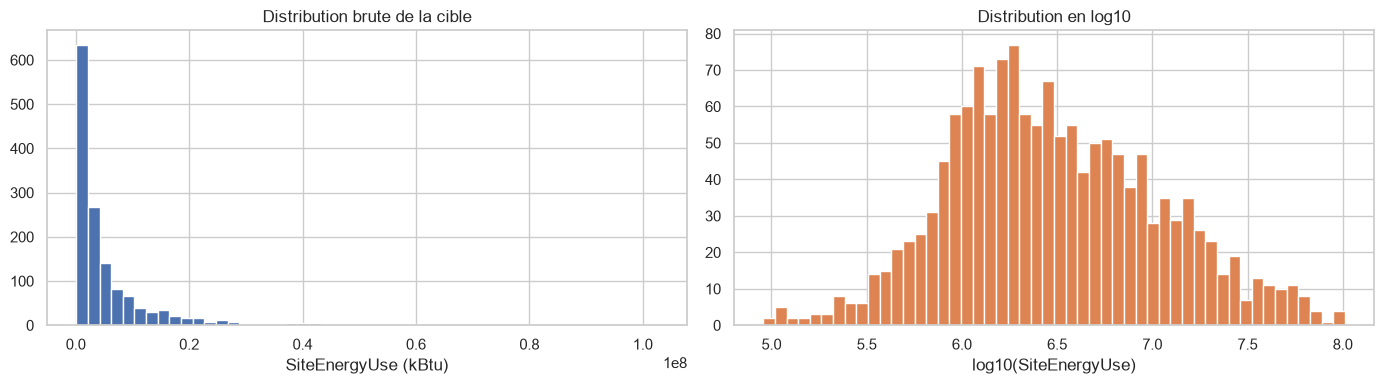

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df[TARGET], bins=50, color="#4c72b0", edgecolor="white")
axes[0].set_title("Distribution brute de la cible")
axes[0].set_xlabel("SiteEnergyUse (kBtu)")
axes[1].hist(np.log10(df[TARGET]), bins=50, color="#dd8452", edgecolor="white")
axes[1].set_title("Distribution en log10")
axes[1].set_xlabel("log10(SiteEnergyUse)")
plt.tight_layout(); plt.show()

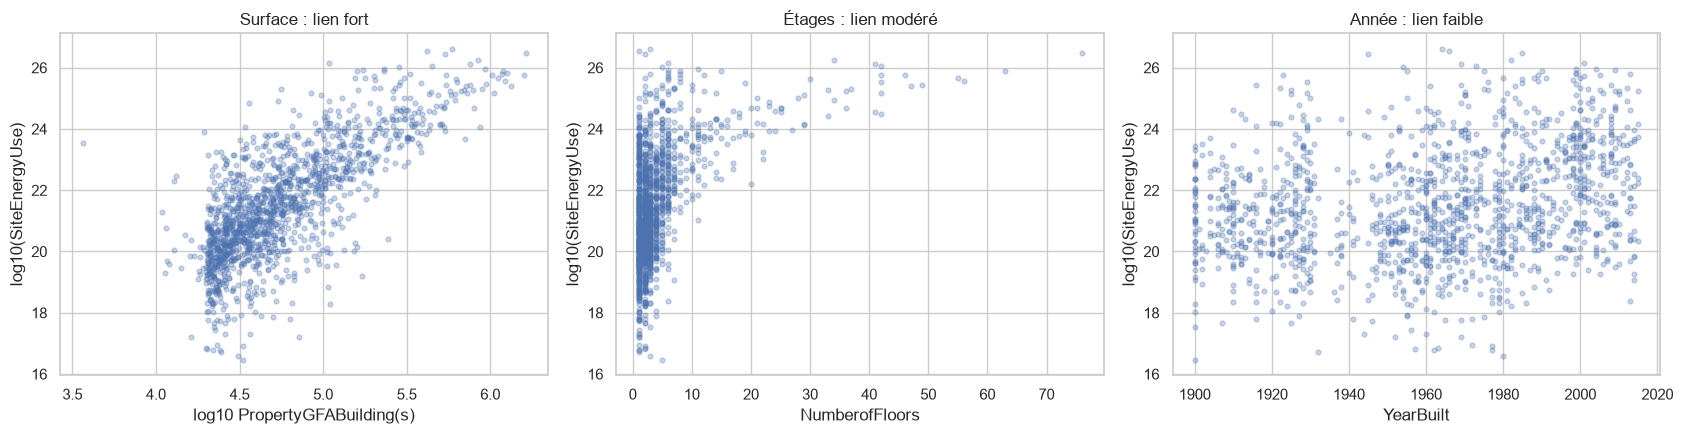

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["PropertyGFABuilding(s)", "NumberofFloors", "YearBuilt"]):
    x = np.log10(df[col]) if col == "PropertyGFABuilding(s)" else df[col]
    ax.scatter(x, np.log2(df[TARGET]), alpha=0.3, s=12)
    ax.set_xlabel(("log10 " if col == "PropertyGFABuilding(s)" else "") + col)
    ax.set_ylabel("log10(SiteEnergyUse)")
axes[0].set_title("Surface : lien fort")
axes[1].set_title("Étages : lien modéré")
axes[2].set_title("Année : lien faible")
plt.tight_layout(); plt.show()

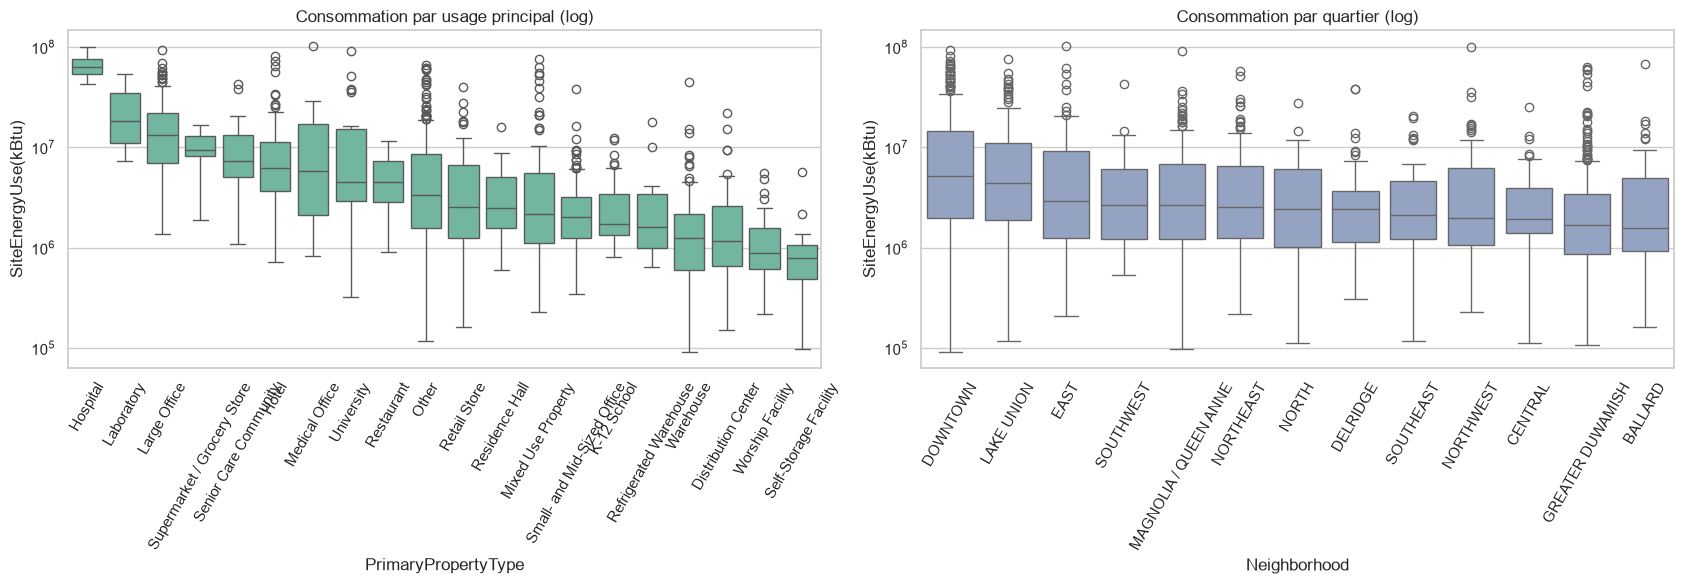

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

order = df.groupby("PrimaryPropertyType")[TARGET].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="PrimaryPropertyType", y=TARGET, order=order, color="#66c2a5", ax=axes[0])
axes[0].set_yscale("log"); axes[0].tick_params(axis="x", rotation=60)
axes[0].set_title("Consommation par usage principal (log)")

order_n = df.groupby("Neighborhood")[TARGET].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Neighborhood", y=TARGET, order=order_n, color="#8da0cb", ax=axes[1])
axes[1].set_yscale("log"); axes[1].tick_params(axis="x", rotation=60)
axes[1].set_title("Consommation par quartier (log)")
plt.tight_layout(); plt.show()

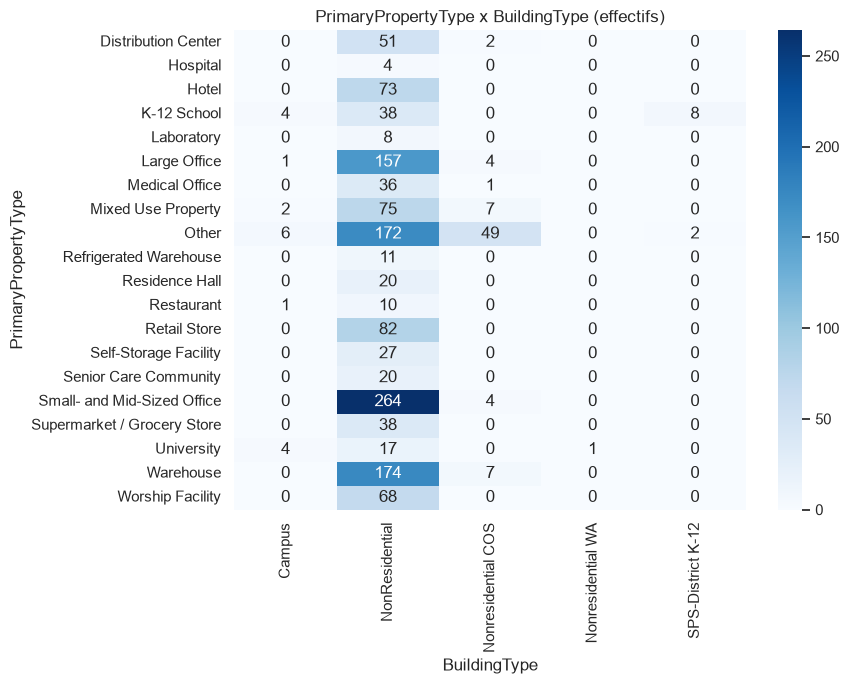

In [36]:
ct = pd.crosstab(df["PrimaryPropertyType"], df["BuildingType"])
plt.figure(figsize=(9, 7))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("PrimaryPropertyType x BuildingType (effectifs)")
plt.tight_layout(); plt.show()

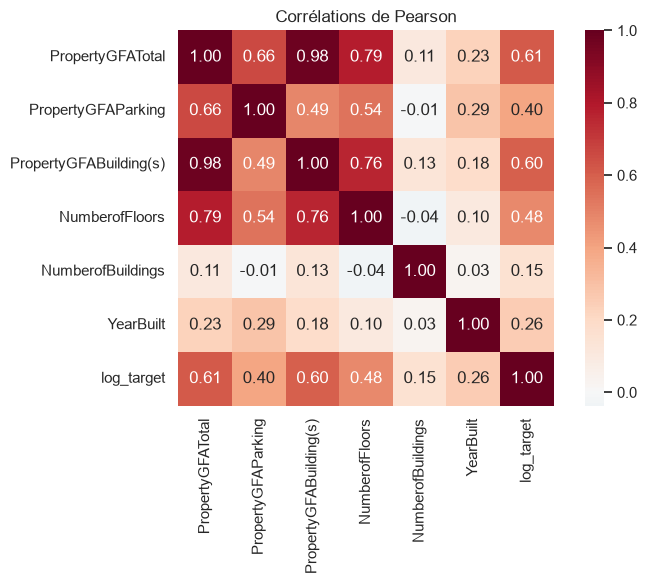

In [37]:
corr_df = df[["PropertyGFATotal", "PropertyGFAParking", "PropertyGFABuilding(s)",
              "NumberofFloors", "NumberofBuildings", "YearBuilt"]].copy()
corr_df["log_target"] = np.log10(df[TARGET])

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Corrélations de Pearson")
plt.tight_layout(); plt.show()

In [38]:
log_target = np.log10(df[TARGET])
q1, q3 = log_target.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mask_out = (log_target < low) | (log_target > high)

print(f"Seuils : {10**low:,.0f} kBtu / {10**high:,.0f} kBtu -> {mask_out.sum()} outliers")
display(df.loc[mask_out, ["PrimaryPropertyType", "PropertyGFATotal", TARGET]].sort_values(TARGET))

n = len(df)
df = df[~mask_out]
log_step("Suppression des outliers (Tukey sur log10 de la cible)", n, len(df))

Seuils : 84,942 kBtu / 103,497,824 kBtu -> 0 outliers


,PrimaryPropertyType,PropertyGFATotal,SiteEnergyUse(kBtu)


NameError: name 'log_step' is not defined

In [ ]:
log_df = pd.DataFrame(cleaning_log)
display(log_df)
print(f"Lignes initiales : {len(building_consumption)} -> finales : {len(df)} "
      f"({len(building_consumption) - len(df)} supprimées au total)")
print("Colonnes restantes :", df.shape[1])
print("Valeurs manquantes restantes :")
display(df.isna().sum()[lambda s: s > 0].to_frame("nb manquants"))

### Conclusion de l'analyse exploratoire

- Périmètre : bâtiments non résidentiels, `Compliant`, sans incohérence physique ni outlier extrême sur la cible, soit **1 448 bâtiments** (sur 3 376 au départ). Une dernière coupe sur les valeurs extrêmes des features, faite en préparation, ramène le jeu de modélisation à **1 428 bâtiments**.
- Cible : `SiteEnergyUse(kBtu)`, très asymétrique, donc modélisée en **log**.
- La **surface** est le lien le plus net avec la cible (corrélation de Spearman ≈ 0,71 avec le log de la consommation). Le **type d'usage** discrimine fortement. L'âge, les étages et la localisation ont des effets plus modestes et souvent liés à la taille ou à l'usage : on les vérifiera avec l'importance des features.
- Les colonnes de consommation (EUI, gaz, électricité, GHG, ENERGYSTARScore) sont écartées comme features (**fuite de données**).
- Les NaN restants (peu nombreux) seront imputés lors de la modélisation, sur le jeu d'entraînement uniquement.

# Feature Engineering

**Objectif** : enrichir le jeu de données avec de nouvelles variables calculées à partir des colonnes existantes, pour aider le modèle à mieux capter le lien entre un bâtiment et sa consommation.

**Règle d'or** : on ne crée que des variables que l'on peut calculer **sans aucun relevé de consommation** (pas de EUI, gaz, électricité, GHG, ENERGYSTARScore). Sinon, il y aurait fuite de données (*data leakage*) : en production, ces valeurs ne seraient pas connues.

| Famille | Idée |
|---|---|
| Âge | `BuildingAge`, `AgeClass` |
| Usage | `NumUseTypes`, `SecondUseShare`, `LargestUseShare` |
| Surface | `ParkingShare`, `HasParking`, `GFAPerBuilding`, `GFAPerFloor`, `IsHighRise` |
| Transformation log | `LogGFABuilding`, `LogGFAParking` |
| Localisation | `DistDowntownKm` |

In [ ]:
data = df.copy()
print("Shape avant feature engineering :", data.shape)

In [ ]:
# Année de référence = 2016 (année du jeu de données)
data["BuildingAge"] = 2016 - data["YearBuilt"]

# Tranches d'âge (variable qualitative ordonnée, utile pour lire les tendances)
data["AgeClass"] = pd.cut(
    data["BuildingAge"],
    bins=[-1, 20, 50, 80, 200],
    labels=["<=20 ans", "21-50 ans", "51-80 ans", ">80 ans"],
)

data[["YearBuilt", "BuildingAge", "AgeClass"]].head()

**Pourquoi ?** `YearBuilt` est une année brute, peu parlante pour un modèle. L'âge est plus intuitif. Son effet sur la consommation n'est toutefois pas évident (voir les tendances) : un bâtiment ancien n'est pas forcément plus énergivore. Les tranches d'âge servent à observer cet effet.

In [ ]:
# Nombre d'usages distincts listés (ex. "Hotel, Parking, Restaurant" -> 3)
data["NumUseTypes"] = data["ListOfAllPropertyUseTypes"].fillna("").apply(
    lambda s: len([u for u in s.split(",") if u.strip()])
)

# Part de la surface occupée par l'usage principal (bornée à 1 : la déclaration peut dépasser la surface totale)
data["LargestUseShare"] = (data["LargestPropertyUseTypeGFA"] / data["PropertyGFATotal"]).clip(upper=1)

# Part de la surface occupée par le 2e usage (0 si pas de 2e usage)
data["SecondUseShare"] = (data["SecondLargestPropertyUseTypeGFA"] / data["PropertyGFATotal"]).clip(upper=1)

data[["ListOfAllPropertyUseTypes", "NumUseTypes", "LargestUseShare", "SecondUseShare"]].head()

In [ ]:
# Part du parking dans la surface totale + indicateur de présence de parking
data["ParkingShare"] = data["PropertyGFAParking"] / data["PropertyGFATotal"]
data["HasParking"] = (data["PropertyGFAParking"] > 0).astype(int)

# Surface moyenne par bâtiment et par étage
data["GFAPerBuilding"] = data["PropertyGFABuilding(s)"] / data["NumberofBuildings"]
data["GFAPerFloor"] = data["PropertyGFABuilding(s)"] / data["NumberofFloors"]
data["GFAPerFloor"] = data["GFAPerFloor"].replace([np.inf, -np.inf], np.nan)

# NaN >= 10 vaut False : on garde donc NaN pour ne pas classer à tort en "pas high-rise"
data["IsHighRise"] = (data["NumberofFloors"] >= 10).astype(float)
data.loc[data["NumberofFloors"].isna(), "IsHighRise"] = np.nan

# Surfaces en log : atténue l'asymétrie et l'effet des très grands bâtiments
data["LogGFABuilding"] = np.log1p(data["PropertyGFABuilding(s)"])
data["LogGFAParking"] = np.log1p(data["PropertyGFAParking"])

data[["ParkingShare", "HasParking", "GFAPerBuilding", "GFAPerFloor", "IsHighRise", "LogGFABuilding"]].head()

**Pourquoi ?**
- Les surfaces sont très asymétriques (quelques très grands sites), d'où le log.
- Les ratios (`ParkingShare`, `GFAPerFloor`...) décrivent la *forme* du bâtiment indépendamment de sa taille.
- `HasParking` et `IsHighRise` sont des indicateurs simples (0/1) qui capturent des effets de seuil.

In [ ]:
# Centre-ville de Seattle (approximation)
LAT0, LON0 = 47.6062, -122.3321

# Distance approximative en km (1° de latitude ≈ 111,2 km ; la longitude est corrigée par cos(latitude))
data["DistDowntownKm"] = np.sqrt(
    ((data["Latitude"] - LAT0) * 111.2) ** 2
    + ((data["Longitude"] - LON0) * 111.2 * np.cos(np.radians(LAT0))) ** 2
)

data["DistDowntownKm"].describe().round(2).to_frame().T

**Pourquoi ?** Latitude et longitude seules sont peu exploitables par un modèle. La distance au centre-ville résume la localisation en un seul chiffre, avec une idée métier : le centre est plus dense et concentre les grands immeubles de bureaux.


In [ ]:
new_features = [
    "BuildingAge", "NumUseTypes", "LargestUseShare", "SecondUseShare",
    "ParkingShare", "HasParking", "GFAPerBuilding", "GFAPerFloor",
    "IsHighRise", "LogGFABuilding", "LogGFAParking", "DistDowntownKm",
]

display(data[new_features].describe().round(2).T)

print("Valeurs manquantes dans les nouvelles variables :")
display(data[new_features].isna().sum()[lambda s: s > 0].to_frame("nb manquants"))
print("Valeurs infinies :", np.isinf(data[new_features]).sum().sum())
print("Shape après feature engineering :", data.shape)

In [ ]:
data["LogTarget"] = np.log2(data[TARGET])

# Quanti vs quanti : corrélation de Spearman avec la cible
num_new = ["LogGFABuilding", "LogGFAParking", "GFAPerBuilding", "GFAPerFloor", "BuildingAge",
           "NumUseTypes", "LargestUseShare", "SecondUseShare", "ParkingShare", "DistDowntownKm"]
corr_target = data[num_new + ["LogTarget"]].corr(method="spearman")["LogTarget"].drop("LogTarget")
corr_target.sort_values().plot.barh(figsize=(8, 5), color="#4c72b0")
plt.title("Corrélation de Spearman avec log2(consommation)")
plt.tight_layout(); plt.show()

# Quanti vs quali : effet des variables binaires et de la tranche d'âge
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=data, x="AgeClass", y="LogTarget", ax=axes[0], color="#66c2a5")
axes[0].set_title("Consommation par tranche d'âge")
sns.boxplot(data=data, x="HasParking", y="LogTarget", ax=axes[1], color="#8da0cb")
axes[1].set_title("Avec / sans parking")
sns.boxplot(data=data, x="IsHighRise", y="LogTarget", ax=axes[2], color="#fc8d62")
axes[2].set_title("Immeuble de grande hauteur")
plt.tight_layout(); plt.show()

### Bilan du feature engineering

- **13 nouvelles variables** créées (12 numériques ou binaires, plus la tranche d'âge `AgeClass` utilisée pour l'exploration), toutes calculables sans relevé de consommation (aucune fuite de données).
- `LogGFABuilding` est la plus liée à la cible, ce qui confirme que la **surface** domine.
- `HasParking` et `IsHighRise` séparent des groupes de consommation différents.
- `BuildingAge` et `DistDowntownKm` ont un lien modéré avec la cible (corrélations de Spearman d'environ −0,27 et −0,28), nettement inférieur à celui de la surface.
- Plusieurs variables sont redondantes entre elles (`PropertyGFATotal`, `PropertyGFABuilding(s)`, `GFAPerBuilding`…) : on les triera avec la matrice de corrélation.

# Préparation des features pour la modélisation

Étapes :
1. Retirer les colonnes inutiles ou **leaky** (liées à la consommation).
2. Traiter les valeurs extrêmes des features, avec des seuils sur quantiles.
3. Examiner la cible et dégager des tendances.
4. Éliminer les features redondantes (matrice de corrélation, **variables numériques uniquement**).
5. Séparer X et y, puis encoder les variables qualitatives.

In [ ]:
LEAKY_COLUMNS = [
    "SiteEnergyUseWN(kBtu)", "SiteEUI(kBtu/sf)", "SiteEUIWN(kBtu/sf)",
    "SourceEUI(kBtu/sf)", "SourceEUIWN(kBtu/sf)",
    "SteamUse(kBtu)", "Electricity(kWh)", "Electricity(kBtu)",
    "NaturalGas(therms)", "NaturalGas(kBtu)",
    "GHGEmissionsIntensity",  # TotalGHGEmissions conservée pour l'extension double cible
    "ENERGYSTARScore", "YearsENERGYSTARCertified",
]
NOT_RELEVANT = [
    "OSEBuildingID", "CouncilDistrictCode",          # identifiants
    "Latitude", "Longitude",                          # résumés par DistDowntownKm
    "YearBuilt",                                      # résumé par BuildingAge
    "ListOfAllPropertyUseTypes",                      # résumé par NumUseTypes
    "SecondLargestPropertyUseType", "ThirdLargestPropertyUseType",
    "SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseTypeGFA",
]

data = data.drop(columns=[c for c in LEAKY_COLUMNS + NOT_RELEVANT if c in data.columns])
print("Shape :", data.shape)
print("Colonnes restantes :", data.columns.tolist())

**Arguments** : les colonnes de consommation (EUI, gaz, électricité, vapeur, GHG) sont calculées **à partir** de la consommation. Les donner au modèle reviendrait à lui donner la réponse. `ENERGYSTARScore` et la certification dépendent aussi de la performance mesurée. Les identifiants n'ont pas de valeur prédictive, et les colonnes brutes ont déjà été résumées .

In [ ]:
extreme_cols = ["NumberofBuildings", "GFAPerFloor", "NumUseTypes"]

mask_extreme = pd.Series(False, index=data.index)
for col in extreme_cols:
    seuil = data[col].quantile(0.995)
    n_col = (data[col] > seuil).sum()
    print(f"{col} : seuil 99,5 % = {seuil:,.1f} -> {n_col} bâtiments au-dessus")
    mask_extreme |= data[col] > seuil

n = len(data)
data = data[~mask_extreme]
log_step("Suppression des valeurs extrêmes de features (quantile 99,5 %)", n, len(data))

**Argument** : un IQR ou un z-score supprimerait trop de bâtiments, car ces variables sont très asymétriques. On coupe donc seulement le **0,5 % supérieur** : on retire les cas vraiment atypiques (campus de 27 bâtiments, 13 usages…) sans réduire le jeu de données.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(data[TARGET], bins=50, color="#4c72b0", edgecolor="white")
axes[0].set_title(f"Cible brute (skewness = {data[TARGET].skew():.1f})")
axes[1].hist(np.log1p(data[TARGET]), bins=50, color="#dd8452", edgecolor="white")
axes[1].set_title(f"log1p(cible) (skewness = {np.log1p(data[TARGET]).skew():.1f})")
plt.tight_layout(); plt.show()

In [ ]:
data["LogTarget"] = np.log10(data[TARGET])

# Par usage principal : médiane de la consommation
display(
    data.groupby("PrimaryPropertyType")[TARGET].agg(["count", "median"])
    .sort_values("median", ascending=False).round(0)
)

# Par tranche d'âge et par présence de parking
display(data.groupby("AgeClass", observed=True)[TARGET].median().round(0).to_frame("médiane"))
display(data.groupby("HasParking")[TARGET].median().round(0).to_frame("médiane"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(data["LogGFABuilding"], data["LogTarget"], alpha=0.3, s=12)
axes[0].set_xlabel("log(surface du bâtiment)"); axes[0].set_ylabel("log10(consommation)")
axes[0].set_title("Plus le bâtiment est grand, plus il consomme")
sns.boxplot(data=data, x="NumUseTypes", y="LogTarget", ax=axes[1], color="#8da0cb")
axes[1].set_title("Consommation selon le nombre d'usages")
plt.tight_layout(); plt.show()

**Tendances observées** :
- **Surface** : c'est le lien le plus net (corrélation de Spearman ≈ 0,71 avec le log de la consommation).
- **Usage** : les médianes les plus élevées sont celles des hôpitaux (≈ 57,8 M kBtu, mais seulement **3 bâtiments** après suppression des outliers), des laboratoires (≈ 18,2 M), des grands bureaux (≈ 13,2 M) et des supermarchés (≈ 9,3 M). Les plus basses sont celles des lieux de culte (≈ 0,9 M), des self-storage (≈ 0,8 M), des centres de distribution et des entrepôts (≈ 1,1 à 1,2 M). Les universités sont en position intermédiaire (≈ 3,5 M).
- **Âge** : l'effet n'est **pas monotone**. Les bâtiments de 20 ans ou moins consomment le plus (médiane ≈ 6,5 M kBtu), contre ≈ 1,8 M pour les 51-80 ans. Ils sont aussi plus grands (surface médiane ≈ 104 k contre 36 à 47 k pour les autres tranches) et comptent plus de grands bureaux (23 % contre 3 à 14 %) : l'effet de l'âge est en grande partie lié à la taille et à l'usage.
- **Parking** : les bâtiments avec parking consomment davantage (médiane ≈ 6,8 M contre ≈ 2,0 M), mais ils sont aussi nettement plus grands (surface médiane ≈ 127 k contre ≈ 39 k).
- **Localisation** : la distance au centre-ville est faiblement et négativement liée à la consommation (Spearman ≈ −0,28).

In [ ]:
num_candidates = [
    "PropertyGFATotal", "PropertyGFABuilding(s)", "PropertyGFAParking", "LargestPropertyUseTypeGFA",
    "LogGFABuilding", "LogGFAParking", "GFAPerBuilding", "GFAPerFloor",
    "NumberofFloors", "NumberofBuildings", "BuildingAge", "NumUseTypes",
    "LargestUseShare", "SecondUseShare", "ParkingShare", "DistDowntownKm",
]
corr = data[num_candidates].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, annot_kws={"size": 7})
plt.title("Corrélations de Pearson (variables numériques)")
plt.tight_layout(); plt.show()

# Paires fortement corrélées (|r| > 0,8)
paires = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(num_candidates)
          for b in num_candidates[i + 1:] if abs(corr.loc[a, b]) > 0.8]
display(pd.DataFrame(paires, columns=["var 1", "var 2", "corrélation"]))

**Lecture** : les surfaces brutes (`PropertyGFATotal`, `PropertyGFABuilding(s)`, `LargestPropertyUseTypeGFA`) sont quasi identiques (r ≥ 0,94) et corrélées à `GFAPerBuilding`. On ne garde que **`LogGFABuilding`**, plus symétrique. `LogGFAParking` et `ParkingShare` sont aussi très liées (r ≈ 0,9) : on garde `ParkingShare` + `HasParking`.

⚠️ La corrélation de Pearson ne s'applique **qu'aux variables numériques**. Pour les variables qualitatives (usage, quartier…), on utilise des boxplots ou des tableaux croisés.

In [ ]:
def controle_qualite(frame, name="jeu"):
    """Échoue si une anomalie corrigée plus haut réapparaît."""
    assert (frame["NumberofBuildings"] > 0).all(), "NumberofBuildings <= 0 présent"
    assert not np.isinf(frame.select_dtypes("number")).any().any(), "Valeur infinie présente"
    assert (frame["NumberofFloors"].dropna() > 0).all(), "NumberofFloors = 0 présent"
    assert (frame["NumberofFloors"].dropna() <= MAX_FLOORS).all(), "Étages aberrants présents"
    print(f"{name} : contrôle OK ({len(frame)} lignes, "
          f"{frame['NumberofFloors'].isna().sum()} étages à imputer dans le Pipeline)")

controle_qualite(data, "data")

In [ ]:
numeric_features = [
    "LogGFABuilding", "NumberofFloors", "NumberofBuildings", "GFAPerFloor",
    "BuildingAge", "NumUseTypes", "LargestUseShare", "SecondUseShare",
    "ParkingShare", "DistDowntownKm", "HasParking", "IsHighRise",
]
categorical_features = ["BuildingType", "PrimaryPropertyType", "Neighborhood", "LargestPropertyUseType"]

X = data[numeric_features + categorical_features]
y = data[TARGET]
print("X :", X.shape, "| y :", y.shape)

print("\nValeurs manquantes à imputer :")
display(X.isna().sum()[lambda s: s > 0].to_frame("nb manquants"))
print("\nNombre de modalités par variable qualitative :")
display(X[categorical_features].nunique().to_frame("modalités"))

### OneHotEncoder ou LabelEncoder ?

- **LabelEncoder** (0, 1, 2…) crée un **ordre artificiel** : le modèle croirait que `DOWNTOWN` (3) > `BALLARD` (1). Il convient aux **variables ordinales** (ex. petit < moyen < grand) ou à la cible.
- **OneHotEncoder** crée une colonne 0/1 par modalité, sans ordre. Il convient aux **variables nominales** (usage, quartier, type de bâtiment).
- Pour une variable à **beaucoup de modalités** (`LargestPropertyUseType`, ~50), on utilise `max_categories` : les modalités rares sont regroupées dans « infrequent », ce qui évite des dizaines de colonnes quasi vides.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

# 20 % de test, mis de côté jusqu'à l'évaluation finale
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train :", X_train.shape[0], "| Test :", X_test.shape[0])

# Imputation et scaling sont APPRIS sur le train uniquement (pas de fuite vers le test)
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", max_categories=15, sparse_output=False)),
    ]), categorical_features),
])

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
print("Train encodé :", X_train_enc.shape, "| Test encodé :", X_test_enc.shape)
print("NaN restants :", np.isnan(X_train_enc).sum())

### Questions qu'on pourrait me poser

| Question | Réponse |
|---|---|
| Pourquoi retirer `ENERGYSTARScore`, `Electricity`, `NaturalGas` ? | Ces valeurs sont calculées à partir de la consommation ou la reflètent : le modèle « tricherait ». En production, on ne les a pas. |
| Pourquoi ne pas supprimer toutes les lignes avec NaN ? | On perdrait trop de bâtiments. On impute (médiane ou modalité la plus fréquente), sur le train seulement. |
| Pourquoi un seuil à 99,5 % pour les extrêmes ? | IQR et z-score retirent trop de bâtiments sur des variables asymétriques. Les quantiles gardent presque tout le jeu de données. |
| Pourquoi OneHot et pas LabelEncoder ? | Quartier et usage sont nominaux : un numéro imposerait un ordre qui n'existe pas. |
| Pourquoi `max_categories` ? | Une variable à ~50 modalités ferait exploser le nombre de colonnes. On regroupe les rares. |
| Pourquoi imputer après le split ? | Pour que la médiane vienne du train. Sinon des infos du test fuiraient vers l'entraînement. |
| Pourquoi la matrice de corrélation seulement sur le numérique ? | Pearson mesure un lien linéaire entre deux nombres. Elle n'a pas de sens sur des catégories. |

# Comparaison de différents modèles supervisés

**Démarche (identique pour tous les modèles)** :
- Mêmes données : `X_train` / `y_train` (même nombre de lignes, même séparation).
- Même validation : **validation croisée à 5 plis**, avec `random_state` fixé.
- Mêmes métriques : **R²**, **MAE** et **RMSE**, calculées sur le train et sur la validation.
- Même prétraitement, intégré dans un `Pipeline` : l'imputation et le scaling sont réappris à chaque pli, donc aucune fuite de données.
- Paramètres par défaut pour chaque algorithme (l'optimisation viendra en mission 5).

**Cible en log** : la consommation est très asymétrique. Le modèle apprend `log1p(consommation)` puis ses prédictions sont reconverties en kBtu (`TransformedTargetRegressor`). Les métriques restent exprimées en kBtu.

**Surapprentissage (*overfit*)** : un modèle qui a un excellent R² sur le train mais un R² bien plus faible en validation a « appris par cœur ».


In [ ]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [ ]:
# 1. Définition des paramètres de validation croisée et des métriques
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

# 2. Définition du transformateur personnalisé
class FloorsImputer(BaseEstimator, TransformerMixin):
    """Remplace les NaN de NumberofFloors par la médiane de son PrimaryPropertyType,
    puis recalcule GFAPerFloor et IsHighRise (colonnes de X : LogGFABuilding, etc.)."""

    def fit(self, X, y=None):
        self.global_median_ = X["NumberofFloors"].median()
        self.median_by_type_ = X.groupby("PrimaryPropertyType")["NumberofFloors"].median()
        return self

    def transform(self, X):
        X = X.copy()
        fill = X["PrimaryPropertyType"].map(self.median_by_type_).fillna(self.global_median_)
        X["NumberofFloors"] = X["NumberofFloors"].fillna(fill).round().clip(lower=1)
        X["GFAPerFloor"] = np.expm1(X["LogGFABuilding"]) / X["NumberofFloors"]
        X["IsHighRise"] = (X["NumberofFloors"] >= 10).astype(int)
        return X
def make_model(estimator):
    """Pipeline complet : FloorsImputer -> prétraitement -> modèle, avec cible modélisée en log."""
    return TransformedTargetRegressor(
        regressor=Pipeline([
            ("floors", FloorsImputer()),  # 1. On impute et crée les colonnes sur le DataFrame brut
            ("prep", preprocessor),       # 2. Ensuite seulement, on applique le préprocesseur scikit-learn
            ("model", estimator)          # 3. Enfin, le modèle d'estimation
        ]),
        func=np.log1p,
        inverse_func=np.expm1,
    )

def evaluate_model(name, estimator, X=X_train, y=y_train):
    """Validation croisée complète d'un modèle ; renvoie une ligne de résultats."""
    res = cross_validate(
        make_model(estimator), X, y,
        cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1,
    )
    return {
        "Modèle": name,
        "R² train": res["train_r2"].mean(),
        "R² validation": res["test_r2"].mean(),
        "Écart R² (train - val.)": res["train_r2"].mean() - res["test_r2"].mean(),
        "MAE validation": -res["test_mae"].mean(),
        "RMSE validation": -res["test_rmse"].mean(),
        "Écart-type R² val.": res["test_r2"].std(),
        "Temps d'entraînement (s)": res["fit_time"].mean(),
    }

print("Mêmes données pour tous les modèles :", X_train.shape, y_train.shape)

In [ ]:
lin_result = evaluate_model("Régression linéaire", LinearRegression())
display_df = pd.Series(lin_result).apply(
    lambda x: round(x, 3) if isinstance(x, (int, float)) else x
).to_frame("valeur")
display(display_df)

**Lecture** : la régression linéaire sert de **référence simple** : elle suppose que la cible s'exprime comme une somme pondérée des features. Elle est rapide et interprétable. Un modèle **non linéaire** (arbres, SVM à noyau RBF) peut capter des effets de seuil et des interactions (ex. : l'effet de la surface dépend de l'usage).

In [ ]:
models = {
    "Dummy (référence)": DummyRegressor(strategy="mean"),
    "Régression linéaire": LinearRegression(),
    "SVR (noyau RBF)": SVR(),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

results = pd.DataFrame([evaluate_model(name, est) for name, est in models.items()]).set_index("Modèle")
display(results.round(3))

print(f"\nConsommation moyenne du train : {y_train.mean():,.0f} kBtu | médiane : {y_train.median():,.0f} kBtu")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

results[["R² train", "R² validation"]].plot.bar(ax=axes[0], rot=30, color=["#a6cee3", "#1f78b4"])
axes[0].set_title("R² (plus haut = mieux)")

results["MAE validation"].plot.bar(ax=axes[1], rot=30, color="#dd8452")
axes[1].set_title("MAE en kBtu (plus bas = mieux)")

results["RMSE validation"].plot.bar(ax=axes[2], rot=30, color="#66c2a5")
axes[2].set_title("RMSE en kBtu (plus bas = mieux)")

for ax in axes:
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [ ]:
overfit = results["Écart R² (train - val.)"].sort_values(ascending=False)
overfit.plot.barh(figsize=(8, 3.5), color="#e15759")
plt.title("Écart de R² entre train et validation (surapprentissage)")
plt.xlabel("R² train - R² validation")
plt.tight_layout(); plt.show()

### Lecture des résultats

- **Dummy** : plancher de performance (R² ≈ −0,12 en validation). Tout modèle qui fait mieux a un vrai pouvoir prédictif.
- **Régression linéaire** : déjà solide (R² validation ≈ 0,63, MAE ≈ 2,91 M, RMSE ≈ 6,45 M), avec très peu de surapprentissage (écart train/validation ≈ 0,07).
- **SVR** : en retrait (R² validation ≈ 0,55, MAE ≈ 2,95 M, RMSE ≈ 7,14 M), avec un écart train/validation de ≈ 0,19.
- **Random Forest** : meilleurs chiffres bruts (R² validation ≈ 0,645, MAE ≈ 2,83 M, RMSE ≈ 6,35 M), mais **le plus fort surapprentissage** (R² train ≈ 0,92 contre ≈ 0,65 en validation, écart ≈ 0,27).
- **Gradient Boosting** : R² validation ≈ 0,62, MAE ≈ 2,86 M, RMSE ≈ 6,56 M, surapprentissage intermédiaire (écart ≈ 0,17).

**La régression linéaire, la Random Forest et le Gradient Boosting sont à égalité** : leurs R² de validation diffèrent de moins de 0,03 (0,62 à 0,645), alors que l'écart-type d'un pli à l'autre est de 0,08 à 0,09. Aucun n'est significativement meilleur. Seul le SVR est nettement en retrait.

**Sens métier** : en validation, une MAE d'environ 2,8 à 2,9 millions de kBtu correspond à une erreur moyenne d'environ **0,83 à 0,86 GWh par an** (1 kBtu ≈ 0,293 kWh). Elle est du même ordre que la consommation médiane (≈ 2,7 M kBtu), car les très gros bâtiments pèsent beaucoup dans la MAE.

**Choix pour la suite** : on retient le **Gradient Boosting**, non parce qu'il est nettement meilleur (la Random Forest est légèrement devant sur toutes les métriques brutes, mais surapprend davantage), mais parce qu'il a plusieurs hyperparamètres à optimiser (profondeur, taux d'apprentissage, nombre d'arbres), contrairement à la régression linéaire. La question est de savoir si un réglage fin lui permet de dépasser nettement la référence linéaire.


In [ ]:
# --- Test d'ablation : chaque groupe de variables apporte-t-il quelque chose ? ---
def make_model_with(num_cols, estimator):
    """Même pipeline que make_model, mais avec une liste de variables numériques réduite.
    FloorsImputer tourne sur X complet ; le ColumnTransformer écarte ensuite les colonnes non listées."""
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                   max_categories=15, sparse_output=False))]),
         categorical_features),
    ])
    return TransformedTargetRegressor(
        regressor=Pipeline([("floors", FloorsImputer()), ("prep", prep), ("model", estimator)]),
        func=np.log1p, inverse_func=np.expm1,
    )

floors_group = ["NumberofFloors", "GFAPerFloor", "IsHighRise"]   # dérivées des étages
without = lambda drop: [c for c in numeric_features if c not in drop]

scenarios = {
    "Référence (toutes les variables)": numeric_features,
    "- NumberofBuildings": without(["NumberofBuildings"]),
    "- Étages (3 variables)": without(floors_group),
    "- Les deux": without(floors_group + ["NumberofBuildings"]),
}

rows, r2_ref = [], None
for name, cols in scenarios.items():
    res = cross_validate(
        make_model_with(cols, GradientBoostingRegressor(random_state=RANDOM_STATE)),
        X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1,
    )
    r2 = res["test_r2"]
    r2_ref = r2 if r2_ref is None else r2_ref
    rows.append({
        "Scénario": name,
        "R² validation": r2.mean(),
        "Δ R² vs référence": (r2 - r2_ref).mean(),
        "Écart-type du Δ (plis)": (r2 - r2_ref).std(),
        "RMSE validation (kBtu)": -res["test_rmse"].mean(),
    })

display(pd.DataFrame(rows).set_index("Scénario").round(3))

# Optimisation et interprétation du modèle

**Modèle retenu en mission 4** : Gradient Boosting.

Démarche :
1. **Test de la grille** sur quelques combinaisons, pour vérifier que le code tourne.
2. **GridSearchCV** sur au moins 3 hyperparamètres (grille de 100 à 500 combinaisons maximum).
3. **Évaluation finale** sur le jeu de test, resté vierge jusqu'ici.
4. **Importance des features**, seulement une fois l'optimisation terminée.

In [ ]:
import time
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

base_model = make_model(GradientBoostingRegressor(random_state=RANDOM_STATE))

# Les noms de paramètres suivent le chemin : TransformedTargetRegressor -> Pipeline -> étape "model"
small_grid = {
    "regressor__model__n_estimators": [100, 200],
    "regressor__model__learning_rate": [0.05, 0.1],
    "regressor__model__max_depth": [2, 3, 4],
}

t0 = time.time()
small_search = GridSearchCV(base_model, small_grid, cv=cv,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
small_search.fit(X_train, y_train)
print(f"Test réussi : 12 combinaisons en {time.time() - t0:.0f} s")
print("Meilleurs paramètres (petit test) :", small_search.best_params_)

In [ ]:
param_grid = {
    "regressor__model__n_estimators": [100, 200, 300, 400],
    "regressor__model__learning_rate": [0.05, 0.1, 0.15],
    "regressor__model__max_depth": [1, 2, 3],
    "regressor__model__min_samples_leaf": [5, 10, 20],
}

n_combos = int(np.prod([len(v) for v in param_grid.values()]))
print(f"{n_combos} combinaisons x {cv.get_n_splits()} plis = {n_combos * cv.get_n_splits()} entraînements")
assert n_combos <= 500, "Grille trop grande : réduire le nombre de combinaisons"

t0 = time.time()
grid = GridSearchCV(
    base_model, param_grid, cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1, return_train_score=True,
)
grid.fit(X_train, y_train)
print(f"Terminé en {(time.time() - t0) / 60:.1f} min")

best_model = grid.best_estimator_
print("Meilleurs hyperparamètres :", grid.best_params_)
print(f"Meilleur RMSE (validation croisée) : {-grid.best_score_:,.0f} kBtu")

**Remarque** : la meilleure combinaison de la première grille est `n_estimators = 400`, `learning_rate = 0,1`, `max_depth = 2` et `min_samples_leaf = 5`. Deux de ces valeurs sont **aux bords de la grille** (`n_estimators = 400` = maximum, `min_samples_leaf = 5` = minimum), donc l'optimum pourrait se trouver hors de la zone explorée. Les dix meilleures combinaisons ont toutefois des RMSE très proches (6,17 M à 6,28 M). On le vérifie avec une seconde grille, élargie (200 à 800 arbres, taux d'apprentissage de 0,02 à 0,1, profondeur de 2 à 4) : elle retourne **exactement les mêmes hyperparamètres et le même RMSE (6,17 M)**. L'optimum n'est donc pas hors de la zone explorée sur ces axes ; seul `min_samples_leaf = 5` reste au minimum des valeurs testées.


In [ ]:
param_grid_2 = {
    "regressor__model__n_estimators": [200, 400, 600, 800],
    "regressor__model__learning_rate": [0.02, 0.03, 0.05, 0.1],
    "regressor__model__max_depth": [2, 3, 4],
    "regressor__model__min_samples_leaf": [5, 10, 20],
}
n_combos = int(np.prod([len(v) for v in param_grid_2.values()]))
print(f"{n_combos} combinaisons x {cv.get_n_splits()} plis = {n_combos * cv.get_n_splits()} entraînements")
assert n_combos <= 500

grid_2 = GridSearchCV(base_model, param_grid_2, cv=cv, scoring="neg_root_mean_squared_error",
                      n_jobs=-1, return_train_score=True)
grid_2.fit(X_train, y_train)
print("Meilleurs hyperparamètres :", grid_2.best_params_)
print(f"Meilleur RMSE (validation croisée) : {-grid_2.best_score_:,.0f} kBtu "
      f"(contre {-grid.best_score_:,.0f} pour la première grille)")

In [ ]:
cv_res = pd.DataFrame(grid.cv_results_)
cols = ["param_regressor__model__n_estimators", "param_regressor__model__learning_rate",
        "param_regressor__model__max_depth", "param_regressor__model__min_samples_leaf",
        "mean_train_score", "mean_test_score"]
top = cv_res.sort_values("rank_test_score")[cols].head(10).copy()
top.columns = ["n_estimators", "learning_rate", "max_depth", "min_samples_leaf", "RMSE train", "RMSE validation"]
top[["RMSE train", "RMSE validation"]] = -top[["RMSE train", "RMSE validation"]]
display(top.round(3))

In [ ]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    return {
        "R² train": r2_score(y_tr, p_tr), "R² test": r2_score(y_te, p_te),
        "MAE train": mean_absolute_error(y_tr, p_tr), "MAE test": mean_absolute_error(y_te, p_te),
        "RMSE train": np.sqrt(mean_squared_error(y_tr, p_tr)),
        "RMSE test": np.sqrt(mean_squared_error(y_te, p_te)),
    }

# Comparaison avec le même modèle SANS optimisation (paramètres par défaut)
default_model = make_model(GradientBoostingRegressor(random_state=RANDOM_STATE)).fit(X_train, y_train)

final = pd.DataFrame({
    "Gradient Boosting par défaut": evaluate(default_model, X_train, y_train, X_test, y_test),
    "Gradient Boosting optimisé": evaluate(best_model, X_train, y_train, X_test, y_test),
}).T
display(final.round(3))

In [ ]:
pred_test = best_model.predict(X_test)
residuals_log = np.log1p(y_test) - np.log1p(np.clip(pred_test, 0, None))
rel_err = np.abs(pred_test - y_test) / y_test

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(np.log10(y_test), np.log10(np.clip(pred_test, 1, None)), alpha=0.4, s=18)
lims = [np.log10(y_test.min()), np.log10(y_test.max())]
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set_xlabel("log10(consommation réelle)")
axes[0].set_ylabel("log10(consommation prédite)")
axes[0].set_title("Prédictions vs réalité (échelle log)")

axes[1].hist(residuals_log, bins=40, color="#4c72b0", edgecolor="white")
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title("Résidus en log (centrés sur 0 = pas de biais)")
plt.tight_layout(); plt.show()

print(f"Erreur relative médiane : {rel_err.median():.0%}")
print(f"Bâtiments prédits à moins de 50 % d'erreur : {(rel_err < 0.5).mean():.0%}")

**Lecture** :
- L'optimisation apporte un **gain modeste** mais réel :
  - **En validation croisée** : le RMSE passe de **6,56 M** (modèle par défaut) à **6,17 M kBtu** (modèle optimisé).
  - **Sur le jeu de test** : le R² progresse de **0,630 à 0,679**, la MAE baisse de **2,87 M à 2,76 M kBtu** et le RMSE diminue de **6,91 M à 6,44 M kBtu**.
- L'écart de R² entre entraînement et test **reste stable** (**0,136** avant et après optimisation) : le modèle gagne en précision sans aggraver le surapprentissage.
- L'erreur relative médiane est de **37 %**, et **63 %** des bâtiments sont prédits avec moins de 50 % d'erreur.
- **Limite structurelle** : ce plafond de performance provient avant tout des variables disponibles (absence de données d'occupation réelle, d'horaires d'ouverture ou d'équipements techniques), et non d'un défaut de réglage des hyperparamètres.


In [ ]:
gb_pipeline = best_model.regressor_                 # Pipeline(prétraitement -> modèle)
gb = gb_pipeline.named_steps["model"]
feature_names = gb_pipeline.named_steps["prep"].get_feature_names_out()

imp = pd.Series(gb.feature_importances_, index=feature_names)

def origin(col):
    """Regroupe les colonnes OneHot sous le nom de la variable d'origine."""
    col = col.split("__", 1)[1]
    for c in categorical_features:
        if col.startswith(c + "_"):
            return c
    return col

imp_grouped = imp.groupby(origin).sum().sort_values()

plt.figure(figsize=(8, 6))
imp_grouped.plot.barh(color="#4c72b0")
plt.title("Importance des features (Gradient Boosting)\nsomme par variable d'origine")
plt.xlabel("Importance")
plt.tight_layout(); plt.show()

In [ ]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1,
)
perm_imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                        index=X_test.columns).sort_values("mean")

plt.figure(figsize=(8, 6))
plt.barh(perm_imp.index, perm_imp["mean"], xerr=perm_imp["std"], color="#dd8452")
plt.title("Permutation importance (test)\nbaisse du R² quand on mélange la variable")
plt.xlabel("Baisse de R²")
plt.tight_layout(); plt.show()

### Interprétation

- **`LogGFABuilding` domine nettement** : environ 66 % de l'importance native et, de loin, la plus forte baisse de R² en permutation (≈ 1,0, soit plus que le R² du modèle : le R² est mesuré en kBtu, donc mélanger la surface crée des erreurs énormes sur les gros bâtiments). Le modèle estime d'abord la consommation à partir de la **taille** du bâtiment.
- **L'usage** (`PrimaryPropertyType` et `LargestPropertyUseType`) représente environ 21 % de l'importance native (≈ 11 % et ≈ 10 %) et arrive juste derrière la surface en permutation (≈ 0,09 chacune).
- **`NumUseTypes`** est faible en importance native (≈ 0,005) mais 4ᵉ en permutation (≈ 0,08) : le nombre d'usages semble utile au modèle, à confirmer car les deux méthodes divergent.
- **`ParkingShare`** (≈ 0,05 en permutation), puis **`NumberofFloors`** (≈ 0,03), **la distance au centre-ville** (≈ 0,03) et **l'âge** (≈ 0,02, aussi ≈ 0,025 en importance native) ont un effet faible.
- **Quasi nuls ou légèrement négatifs en permutation** : `BuildingType` (≈ 0,002), `NumberofBuildings` (≈ −0,001), `Neighborhood` (≈ −0,006) et `LargestUseShare` (≈ −0,01). Le modèle n'en tire pas d'information fiable.
- **`HasParking`** a une importance nulle : il est redondant avec `ParkingShare`.

⚠️ **Artefact à connaître** : `GFAPerFloor` et `IsHighRise` ont une importance par permutation de **exactement 0**. Ce n'est pas un résultat : le transformateur `FloorsImputer` recalcule ces deux colonnes à partir de `NumberofFloors` et de `LogGFABuilding`, donc mélanger les colonnes brutes ne change aucune prédiction. On ne peut rien conclure de la permutation pour ces deux variables (leur importance native est de ≈ 0,009 et 0).

⚠️ Les deux méthodes ne donnent pas le même classement : l'importance native se répartit entre variables corrélées, alors que la permutation mesure l'effet sur la performance. De plus, `LargestPropertyUseType` et `PrimaryPropertyType` sont **redondantes** : leur importance se partage entre les deux.

**Sens métier** : pour estimer la consommation d'un bâtiment non relevé, la **surface** est la donnée essentielle, puis son **usage**. La localisation et l'âge jouent un rôle mineur.


### Limites

- Précision modérée : R² ≈ 0,68 sur le test. Sur le test, la MAE est d'environ 2,76 millions de kBtu (≈ 0,81 GWh par an) ; en validation croisée, les modèles de la mission 4 ont une MAE de 2,8 à 2,95 M (≈ 0,83 à 0,86 GWh). L'erreur relative médiane est de 37 %.
- Les très gros sites (grands hôpitaux, universités) ont en grande partie été exclus : le modèle n'est pas conçu pour eux. Les hôpitaux ne comptent que 3 bâtiments dans les données conservées.
- Une seule année de données (2016), et pas de variables d'occupation ni d'équipements.
- Jeu de test de 286 bâtiments seulement : les métriques de test varient d'un tirage à l'autre.
- Les métriques (R², MAE, RMSE) sont exprimées en kBtu : elles sont dominées par les plus gros bâtiments, alors que le modèle apprend sur le log de la consommation.
- Piste d'amélioration : essayer d'autres familles de modèles (XGBoost, LightGBM) ou enrichir les données.


---
# Extension : Modélisation sur la double cible (`SiteEnergyUse(kBtu)` et `TotalGHGEmissions`)

Conformément à l'objectif de neutralité carbone de Seattle, nous dupliquons ici la démarche de modélisation supervisée sur les **émissions totales de gaz à effet de serre (`TotalGHGEmissions`)** afin de comparer les performances et les facteurs d'influence avec la consommation énergétique (`SiteEnergyUse(kBtu)`).

**Points d'attention spécifiques à `TotalGHGEmissions`** :
- La cible présente également une forte asymétrie (*skewness* élevé), justifiant l'utilisation de `TransformedTargetRegressor` avec `np.log1p` / `np.expm1`.
- Certaines valeurs sont nulles ou légèrement négatives (ex. : le *Bullitt Center* à −0,8 tonne équivalent $CO_2$ grâce à une production nette positive). On filtre `TotalGHGEmissions > 0` afin de comparer les deux cibles sur exactement les mêmes bâtiments (la transformation `log1p` accepterait ces valeurs). Ce filtre ne retire que **2 bâtiments** : le périmètre est de **1 426 bâtiments**, contre 1 428 dans la partie principale. Les chiffres obtenus ici pour la consommation d'énergie diffèrent donc légèrement de ceux de la partie principale (autre découpage train/test).

In [ ]:
# Définition des deux cibles à comparer à périmètre constant
TARGETS = ["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]

# Filtrage des valeurs strictement positives sur les deux cibles (gestion des bâtiments à bilan carbone négatif/nul)
mask_valid_targets = (data["SiteEnergyUse(kBtu)"] > 0) & (data["TotalGHGEmissions"] > 0)
data_dual = data[mask_valid_targets].copy()

X_dual = data_dual[numeric_features + categorical_features]

# Définition des modèles à comparer
dual_models = {
    "Dummy (référence)": DummyRegressor(strategy="mean"),
    "Régression linéaire": LinearRegression(),
    "SVR (noyau RBF)": SVR(),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

dual_results = []

for target_col in TARGETS:
    y_target = data_dual[target_col]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_dual, y_target, test_size=0.2, random_state=RANDOM_STATE
    )
    
    for model_name, est in dual_models.items():
        res = evaluate_model(model_name, est, X=X_tr, y=y_tr)
        res["Cible"] = target_col
        
        # Évaluation complémentaire sur le jeu de test
        fitted_pipe = make_model(est).fit(X_tr, y_tr)
        preds_te = fitted_pipe.predict(X_te)
        res["R² test"] = r2_score(y_te, preds_te)
        res["MAE test"] = mean_absolute_error(y_te, preds_te)
        dual_results.append(res)

df_dual_summary = pd.DataFrame(dual_results)[
    ["Cible", "Modèle", "R² train", "R² validation", "R² test", "MAE validation", "MAE test"]
]
display(df_dual_summary.round(3))

### Lecture des résultats de la double cible

- **Consommation d'énergie** : R² de validation de ≈ 0,64 (régression linéaire), ≈ 0,66 (Random Forest) et ≈ 0,64 (Gradient Boosting) ; le Gradient Boosting atteint un R² de test de ≈ 0,61.
- **Émissions de CO₂** : nettement moins bien prédites, avec un R² de validation d'environ **0,45** (≈ 0,47 pour la linéaire, ≈ 0,44 pour la Random Forest, ≈ 0,45 pour le Gradient Boosting) et un R² de test de ≈ 0,36 à 0,44. Le SVR est le plus faible (R² de test ≈ 0,20).
- La Random Forest surapprend fortement sur les deux cibles (R² train ≈ 0,92 pour l'énergie, ≈ 0,84 pour le CO₂).
- Les **MAE ne sont pas comparables entre les deux cibles** (kBtu contre tonnes d'équivalent CO₂) : seul le R² permet de comparer.
- **Explication probable et piste d'amélioration** : les émissions dépendent surtout du **mix énergétique** (gaz, vapeur) et non de l'énergie totale, car l'électricité à Seattle est fortement décarbonée (hydroélectricité). Aucune feature actuelle n'indique les sources d'énergie installées dans le bâtiment.
  - **Piste** : ajouter des indicateurs structurels `HasGas` et `HasSteam` (un test exploratoire à partir des relevés fait passer le R² de validation du Gradient Boosting de ≈ 0,45 à ≈ 0,51 pour le CO₂).
  - **Point de vigilance (*data leakage*)** : en production, ces variables ne doivent pas être déduites des relevés de compteurs (`NaturalGas(kBtu)`, `SteamUse(kBtu)`) qui constituent des factures énergétiques *a posteriori*, mais provenir d'un registre administratif de raccordement aux réseaux (gaz de ville ou vapeur urbaine).


In [ ]:
# Comparaison de l'importance des variables (Gradient Boosting) entre Énergie et Émissions de CO2
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, target_col in zip(axes, TARGETS):
    y_target = data_dual[target_col]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_dual, y_target, test_size=0.2, random_state=RANDOM_STATE
    )
    
    gb_dual = make_model(GradientBoostingRegressor(random_state=RANDOM_STATE))
    gb_dual.fit(X_tr, y_tr)
    
    perm_dual = permutation_importance(
        gb_dual, X_te, y_te, n_repeats=10, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1
    )
    imp_df = pd.DataFrame({
        "mean": perm_dual.importances_mean,
        "std": perm_dual.importances_std
    }, index=X_te.columns).sort_values("mean")
    
    ax.barh(imp_df.index, imp_df["mean"], xerr=imp_df["std"], color="#1f78b4" if target_col == "SiteEnergyUse(kBtu)" else "#2ca02c")
    ax.set_title(f"Importance par permutation — {target_col}")
    ax.set_xlabel("Baisse moyenne de R²")

plt.tight_layout()
plt.show()